

---

&#10148;<font face="Courier New" size=5 color='green'> ***ECSE 415 Final Project*** <font>

&#10148;<font face="Courier New" size=5 color='green'> ***Author: Group 10*** <font>

&#10148;<font face="Courier New" size=5 color='green'> **Bruno Marcoux (260869395),
Duranjay Kaundun (260836316),
Yazdan Zinati (260928077),
Patrick Juneau (260928476),
Lakshmi Roy (260925369)** <font>


---




In [65]:
#Google Environment

from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/Colab Notebooks/Final_Project/'

#Local Environment

#path = './ECSE415/Final_Project/Final_Project/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
rgb_f = 'QC/rgb/' #path for rgb files
csv_f = 'QC/csv/' #path for csv files
mask_f = 'QC/mask/' #path for mask files

In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
import os
import csv as csv2



---

#&#10148;<font face="serif" size=5 color='cyan'> ***Qu 3:Dataset*** <font>

---



In [ ]:
#Get all file names from RGB folder without extension.
#This assumes tha all files have the same name for CSV and mask

imgs = []
for file_name in os.listdir(path+rgb_f):
  if file_name.endswith(('.png','.PNG','jpeg')):

    #Getting file names without extension
    file_name = os.path.splitext(file_name)[0]
    imgs.append(file_name)


def rgb(file_name):
  '''
  returns BGR image
  input: file name, obtained from imgs[n]
  '''
  file_path = os.path.join(path+rgb_f, file_name+'.png')
  img = cv2.imread(file_path)  
  return img

def get_mask(file_name):
  '''
  returns BGR mask
  input: file name, obtained from imgs[n]
  '''
  file_path = os.path.join(path+mask_f, file_name+'.png')
  img = cv2.imread(file_path)  
  return img

def csv(file_name):
  '''
  returns CSV file path
  input: file name, obtained from imgs[n]
  '''
  file_path = os.path.join(path+csv_f, file_name+'.csv')
  return file_path



---

 #### &#10148;<font face="serif" size=4 color='orange'> Qu 3.1:Plot three images  <font>

---



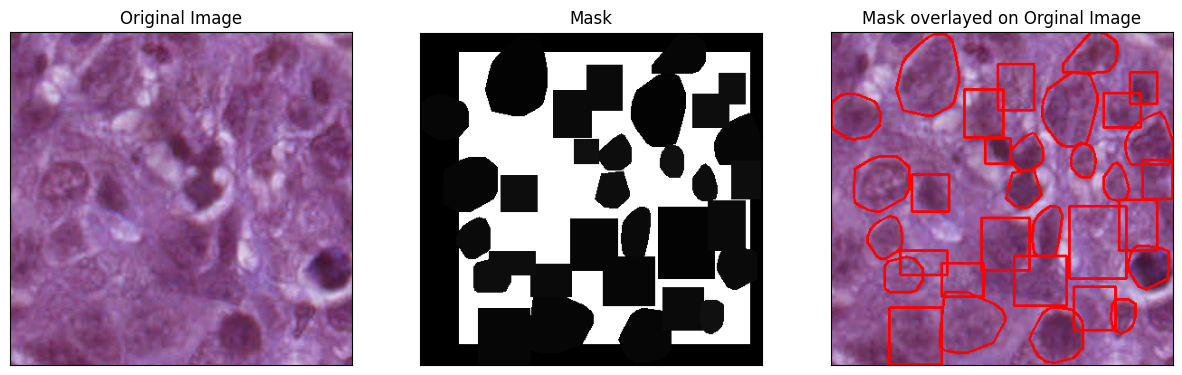

In [ ]:
n = np.random.randint(0,len(imgs)-1)
n = 1012 #same as in assignment pdf
img1 = rgb(imgs[n])
csv1 = csv(imgs[n])
mask1 = get_mask(imgs[n])

#Mask
mask1_gray = cv2.cvtColor(mask1, cv2.COLOR_BGR2GRAY)


#Mask overlayed on original image
def overlay_image(img,csv):
  img_overlay = img.copy()
  with open(csv) as csvfile:
      reader = csv2.reader(csvfile, delimiter=',')
      next(reader) #skip header
      for r in reader:
        # xmin = r[5]
        # ymin = r[6]
        # xmax = r[7]
        # ymax = r[8]
        coords_x = r[9] #in string format
        coords_x = [int(x) for x in coords_x.split(',')] #converting to int
        coords_y = r[10] #in string format
        coords_y = [int(x) for x in coords_y.split(',')] #converting to int

        pts = []
        for i in range(len(coords_x)):
          pts.append([coords_x[i], coords_y[i]])
        pts = np.array(pts)
              
        # Draw the polyline shape
        cv2.polylines(img_overlay, [pts], isClosed=True, color=(255, 0, 0), thickness=2)
  return img_overlay

img1_overlay = overlay_image(img1,csv1)

#plot
plt.figure(figsize=(15,15))
plt.subplot(131), plt.imshow(img1),plt.xticks([]),plt.yticks([]), plt.title("Original Image")
plt.subplot(132), plt.imshow(mask1_gray, cmap="gray"),plt.xticks([]),plt.yticks([]), plt.title("Mask")
plt.subplot(133), plt.imshow(img1_overlay), plt.title("Mask overlayed on Orginal Image"), plt.xticks([]), plt.yticks([])
plt.show()



---

 #### &#10148;<font face="serif" size=4 color='orange'> Qu 3.2:Create training and validation split  <font>

---


In [ ]:
#Find unique patients
ids = []
for str in imgs:
  id = str.split("_id")[0]
  ids.append(id)
print("Total number of samples: {}".format(len(ids)))

ids = list(set(ids)) #converting to set removes any duplicates and then we convert back to list
print("Total number of unique patients: {}".format(len(ids)))

#Split patients into training and validation sets 
n = int(0.8*(len(ids)))
id1 = ids[:n]
id2 = ids[n+1:]

#Create training and validation csv files
csv_path = path + 'splits/train_subjects.csv'

dir_path = os.path.dirname(csv_path)
if not os.path.exists(dir_path):
    os.makedirs(dir_path)

with open(csv_path, 'w', newline='') as file:
    writer = csv2.writer(file)

    # write a header row
    writer.writerow(['ID'])

    # write each ID to a new row in the CSV file
    for id in id1:
        writer.writerow([id])

csv_path = path + 'splits/validate_subjects.csv'

dir_path = os.path.dirname(csv_path)
if not os.path.exists(dir_path):
    os.makedirs(dir_path)

with open(csv_path, 'w', newline='') as file:
    writer = csv2.writer(file)

    # write a header row
    writer.writerow(['ID'])

    # write each ID to a new row in the CSV file
    for id in id2:
        writer.writerow([id])

Total number of samples: 1744
Total number of unique patients: 124


In [ ]:
def dataFromUniqueIDs(train):
  '''
  Returns indices of train or test data(all variations are returned, not only unique ones)
  Inputs:
  Boolean Train: if training images are desired, Train = True
  '''
  unq_ids = []
  csv_path = ''
  if train == True:
    csv_path = path + 'splits/train_subjects.csv'
  elif train == False:
    csv_path = path + 'splits/validate_subjects.csv'

  #verify if dataset exists
  dir_path = os.path.dirname(csv_path)
  if not os.path.exists(dir_path):
    print("dataset does not exist. Please run FindUniqueIDS!")
    return unq_ids

  with open(csv_path, 'r') as file:
    reader = csv2.reader(file)   
    next(reader)  # skip header row

    # read each ID from the CSV file
    for row in reader:
        id = row[0]
        unq_ids.append(id)

    # unique IDs are extracted from csv file. Now we get all variation of the unique file
    IDS = []
    for id in unq_ids:
      for r in range(len(imgs)):
        img = imgs[r]
        if id in img: #verify if file name contains unique ID
          IDS.append(r)

  return IDS



---

#&#10148;<font face="serif" size=5 color='cyan'> ***Qu 4:Segmentation*** <font>

---





---

 #### &#10148;<font face="serif" size=4 color='orange'> Qu 4.1:Segmentation - Unsupervised  <font>

---




---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.1.1: Find an optimized value of K. Show the results for K=3 and K= 5.   <font>

---


682


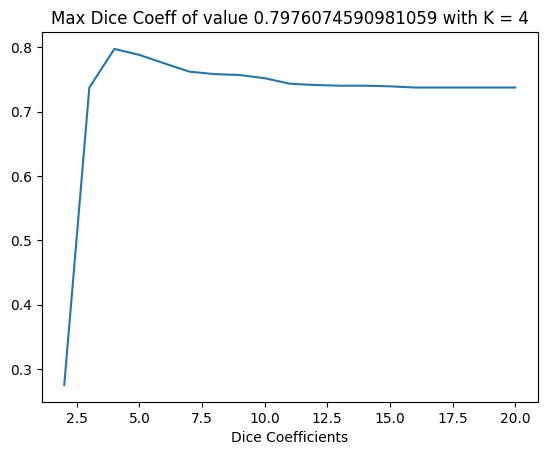

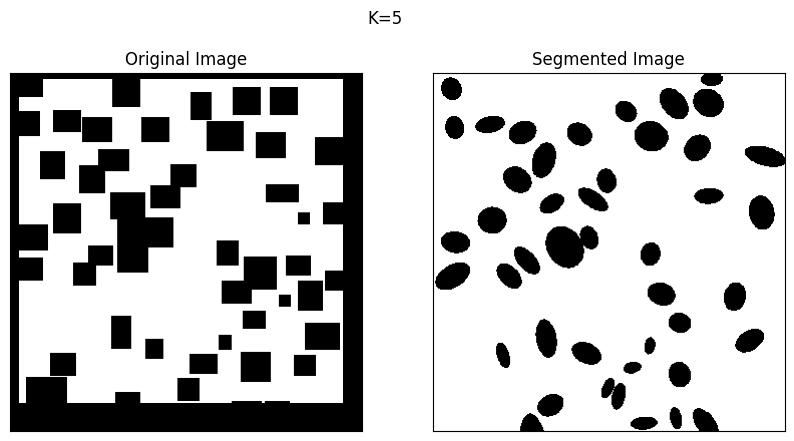

Dice Coeffecient for K=5 is 0.7891623693379791


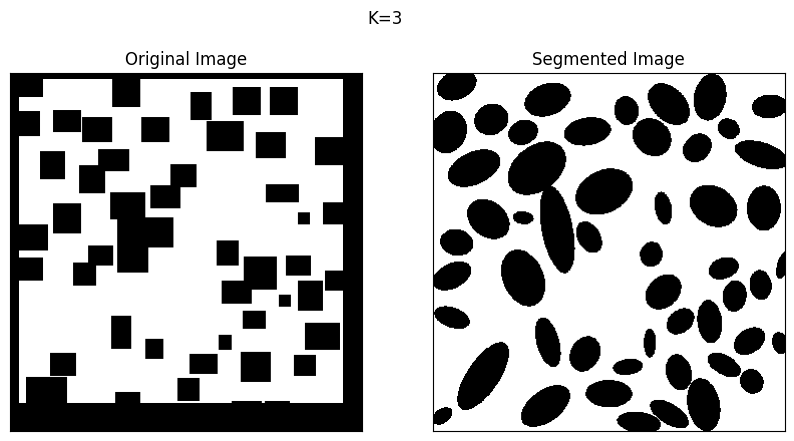

Dice Coeffecient for K=3 is 0.7465230986615728


In [ ]:
def cmpt_dice(img1,img2, K,show=False):
  '''
  img1 is truth mask(GRAY)
  img2 is calculated mask(GRAY)
  '''
  img2 = np.resize(img2, img1.shape)

  img1_mask = cv2.threshold(img1, 60, 255, cv2.THRESH_BINARY)[1]
  img2_mask = cv2.threshold(img2, 60, 255, cv2.THRESH_BINARY_INV)[1]

  # Compute the intersection and union of the two masks
  intersection = np.logical_and(img1_mask, img2_mask)
  union = np.logical_or(img1_mask, img2_mask)
  
  # Compute the Dice coefficient
  dice = (2. * intersection.sum()) / (union.sum() + intersection.sum())

  if show==True:
    #Plot Original Image and and Segmented Image
    plt.figure(figsize=(10,5))
    plt.suptitle("K={}".format(K))
    plt.subplot(121), plt.imshow(img1_mask,cmap='gray'),plt.xticks([]),plt.yticks([]), plt.title("Original Image")
    plt.subplot(122), plt.imshow(img2_mask,cmap='gray'),plt.xticks([]),plt.yticks([]), plt.title("Segmented Image")
    plt.show()

  return dice

def k_means(img, K):
  #Reshape image to flattened array of pixels (3 levels deep for RGB)
  #Convert segmented image to grayscale
  if len(img.shape) == 3:
    Z = img.copy().reshape((-1,3))
  else:
    Z = img.copy().reshape((-1,1))
  
  Z = np.float32(Z)
  criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1)

  #Apply K-means clustering
  ret,label,center=cv2.kmeans(Z,K,None,criteria,10,cv2.KMEANS_PP_CENTERS)

  #Using the output labels, map each point to the colour of its center
  center = np.uint8(center)
  out = center[label.flatten()]
  out = out.reshape((img.shape))  #output image with clustering

  return out

def calc_mask(img1,out):  
  #Convert segmented image to grayscale
  if len(img1.shape) == 3:
    g_disp = cv2.cvtColor(out, cv2.COLOR_RGB2GRAY)
  else:
    g_disp = out

  #Create a mask from only the darkest points (tumor)
  mask_rough = g_disp==np.min(g_disp)

  #Find contours of segmented tumors
  contours, _ = cv2.findContours(mask_rough*g_disp, cv2.RETR_EXTERNAL , cv2.CHAIN_APPROX_SIMPLE)

  #Fit ellipses around the tumor contours
  ellipses = []
  for contour in contours:
    area = cv2.contourArea(contour)
    if len(contour) >= 5:  # Minimum number of points required for ellipse fitting
      if area >= 110:
        ellipse_approx = cv2.fitEllipse(contour)
        ellipses.append(ellipse_approx)
        ellipse = cv2.fitEllipse(contour)
  
  #Create a mask using the ellipses
  mask = np.zeros_like(g_disp)
  for ellipse in ellipses:
    cv2.ellipse(mask, ellipse, (255, 255, 255), -1)
  
  return mask,ellipses


#loading random image
n = np.random.randint(0,len(imgs)-1)
n=682
print(n)
img = rgb(imgs[n]) 
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
mask = get_mask(imgs[n])
mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

#plotting graph to see which K results in higher Dice-Coeff
dice_coeff = []
x=[]
for i in range(2,21):
  out= k_means(img,i)
  d = cmpt_dice(mask,calc_mask(img,out)[0],i)
  dice_coeff.append(d)
  x.append(i)

plt.plot(x, dice_coeff)
plt.xlabel("k")
plt.xlabel("Dice Coefficients")
plt.title("Max Dice Coeff of value {} with K = {}".format(dice_coeff[np.argmax(dice_coeff)],x[np.argmax(dice_coeff)]))
plt.show() 

d5 = cmpt_dice(mask,calc_mask(img,k_means(img,5))[0],5,True)
print("Dice Coeffecient for K=5 is {}".format(d5))
d3 = cmpt_dice(mask,calc_mask(img,k_means(img,3))[0],3,True)
print("Dice Coeffecient for K=3 is {}".format(d3))

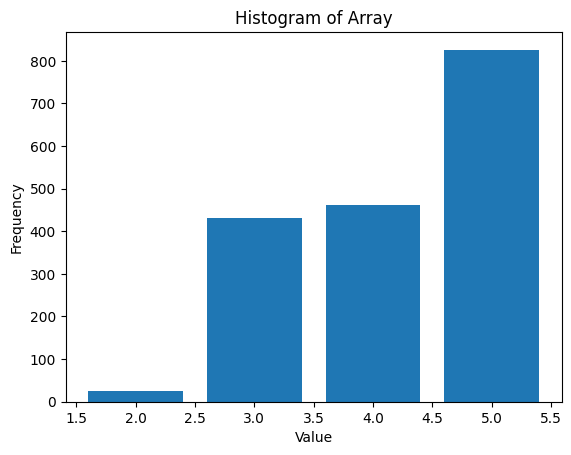

In [ ]:
#optimal K for color images
max = []
for n in range(len(imgs)):
  # n = np.random.randint(0,len(imgs)-1)
  img = rgb(imgs[n]) 
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  # img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  mask = get_mask(imgs[n])
  mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

  #plotting graph to see which K results in higher Dice-Coeff
  dice_coeff = []
  x=[]
  for i in range(2,6):
   out= k_means(img,i)
   d = cmpt_dice(mask,calc_mask(img,out)[0],i)
   dice_coeff.append(d)
   x.append(i)

  x = x[np.argmax(dice_coeff)]
  max.append(x)

max = np.array(max)
# Count the frequency of each unique number
unique, counts = np.unique(max, return_counts=True)

# Plot the histogram
plt.bar(unique, counts)

# Add labels and title
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Histogram of Array')

# Show the plot
plt.show()

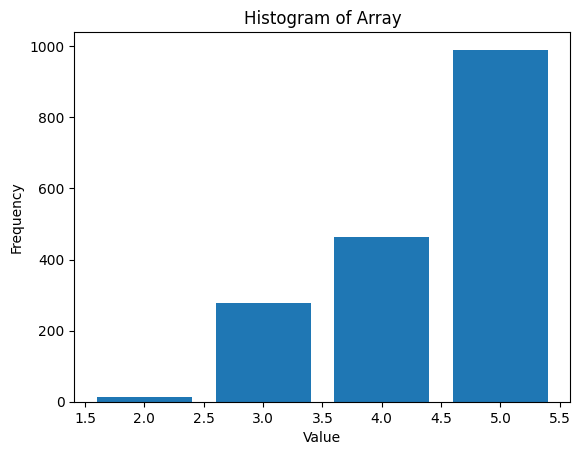

In [ ]:
#optimal K for grayscale
max = []
for n in range(len(imgs)):
  # n = np.random.randint(0,len(imgs)-1)
  img = rgb(imgs[n]) 
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  mask = get_mask(imgs[n])
  mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

  #plotting graph to see which K results in higher Dice-Coeff
  dice_coeff = []
  x=[]
  for i in range(2,6):
   out= k_means(img,i)
   d = cmpt_dice(mask,calc_mask(img,out)[0],i)
   dice_coeff.append(d)
   x.append(i)

  x = x[np.argmax(dice_coeff)]
  max.append(x)

max = np.array(max)
# Count the frequency of each unique number
unique, counts = np.unique(max, return_counts=True)

# Plot the histogram
plt.bar(unique, counts)

# Add labels and title
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Histogram of Array')

# Show the plot
plt.show()



---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.1.2: How did you decide the optimized value of K? Explain your answer in the context of computing DICE coefficients   <font>

---


As shown above, we tested K-means clustering using K=3 and K=5.

From our testing, we found that using a K value of 5 lead to better results. This is supported by the corresponding plots shown above as K=5 has a higher frequency.



---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.1.3: Show (i) the original image, (ii) the segmented image for the optimized value of K. (iii) the ground truth segmentation, available in the csv file corresponding to the image you have chosen.   <font>

---


Chosen sample : 682


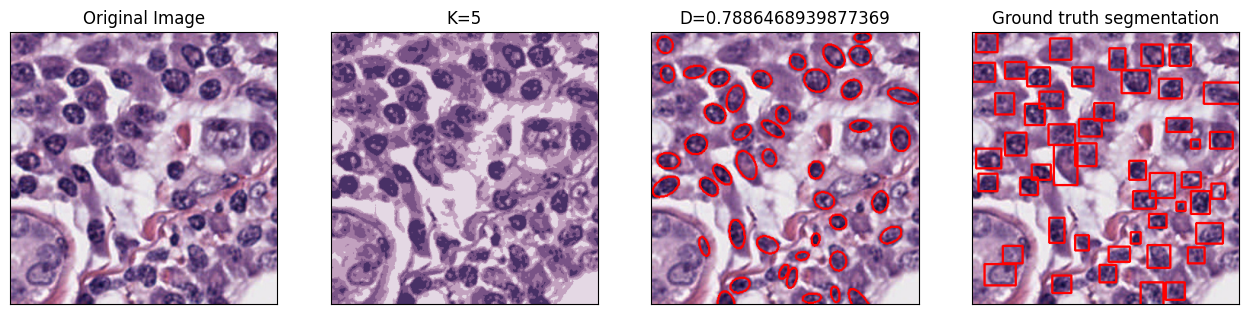

In [ ]:
def segment_kmeans(n):
  img = rgb(imgs[n])
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  csv1 = csv(imgs[n])
  mask_ori = get_mask(imgs[n])
  mask_ori = cv2.cvtColor(mask_ori, cv2.COLOR_BGR2GRAY)

  #Calculate segmented image
  K=5
  out_disp = k_means(img,K)

  #Plot
  plt.figure(figsize=(20,15))
  plt.subplot(151)
  plt.imshow(img)
  plt.title("Original Image"), plt.xticks([]), plt.yticks([])
  plt.subplot(152)
  plt.imshow(out_disp)
  plt.title("K={}".format(K)), plt.xticks([]), plt.yticks([])

  #Create a mask from only the darkest points (tumor)
  mask, ellipses = calc_mask(img,out_disp.copy())

  #Plot mask
  # plt.subplot(153)
  # plt.imshow(mask,cmap='gray')
  # plt.title("Mask"), plt.xticks([]), plt.yticks([])

  #Using mask, detect tumors
  D = cmpt_dice(mask_ori,mask,K)
  plt.subplot(153)
  tumors_kMeans = img.copy()
  for ellipse in ellipses:
      cv2.ellipse(tumors_kMeans, ellipse, (255, 0, 0), 2)
  plt.imshow(tumors_kMeans)
  plt.title("D={}".format(D)), plt.xticks([]), plt.yticks([])

  #Overlay ground truth on original image
  img_disp = overlay_image(img,csv1)

  #Show ground truth
  plt.subplot(154)
  plt.imshow(img_disp)
  plt.title("Ground truth segmentation"), plt.xticks([]), plt.yticks([])
  plt.show()

  return mask;

#Choose random image
n = np.random.randint(0,len(imgs)-1)
n = 682
print("Chosen sample : {}".format(n))

segment_kmeans(n)
print()



---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.1.4: Do your segmentation results improve if you use a grayscale image compared to an RGB image? Show 3 relevant examples to support your answer.   <font>

---


In [ ]:
def segment_kmeans_grayscale(n):
  img = rgb(imgs[n])
  img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  csv1 = csv(imgs[n])
  mask_ori = get_mask(imgs[n])
  mask_ori = cv2.cvtColor(mask_ori, cv2.COLOR_BGR2GRAY) 

  #Calculate segmented image
  K=5
  out_disp = k_means(img,K)

  #Plot
  plt.figure(figsize=(20,15))
  plt.subplot(151)
  plt.imshow(img, cmap="gray")
  plt.title("Original Image"), plt.xticks([]), plt.yticks([])
  plt.subplot(152)
  plt.imshow(out_disp,cmap='gray')
  plt.title("Segmentated Image"), plt.xticks([]), plt.yticks([])


  #Create a mask from only the darkest points (tumor)
  mask, ellipses = calc_mask(img,out_disp.copy())

  # #Plot mask
  # plt.subplot(153)
  # plt.imshow(mask,cmap='gray')
  # plt.title("Mask"), plt.xticks([]), plt.yticks([])

  #Using mask, detect tumors
  D = cmpt_dice(mask_ori,mask,K)
  plt.subplot(153)
  tumors_kMeans = img.copy()
  for ellipse in ellipses:
      cv2.ellipse(tumors_kMeans, ellipse, (255, 0, 0), 2)
  plt.imshow(tumors_kMeans,cmap='gray')
  plt.title("D={}".format(D)), plt.xticks([]), plt.yticks([])

  #Overlay ground truth on original image
  img_disp = overlay_image(img,csv1)

  #Show ground truth
  plt.subplot(154)
  plt.imshow(img_disp,cmap='gray')
  plt.title("Ground truth segmentation"), plt.xticks([]), plt.yticks([])
  plt.show()

  return mask

Compare 3 samples

Chosen sample : 190


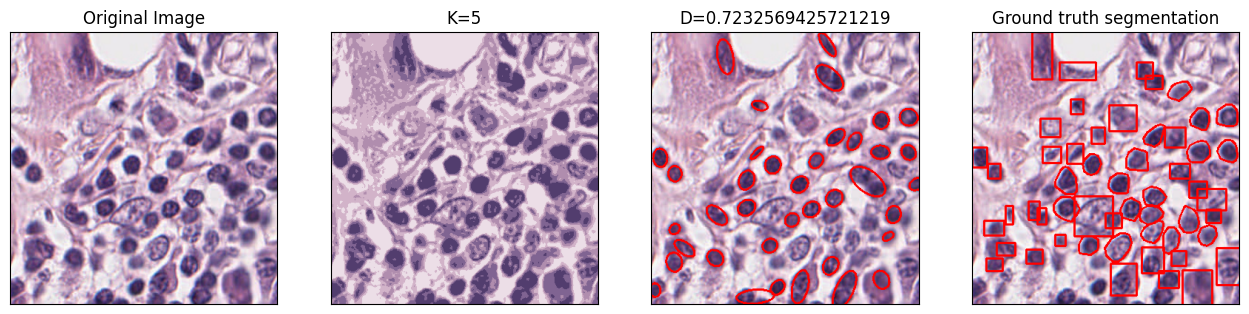

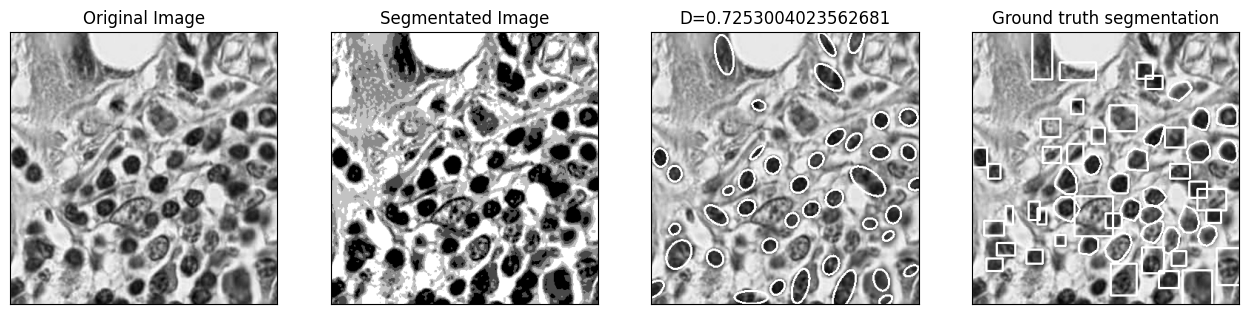

Chosen sample : 727


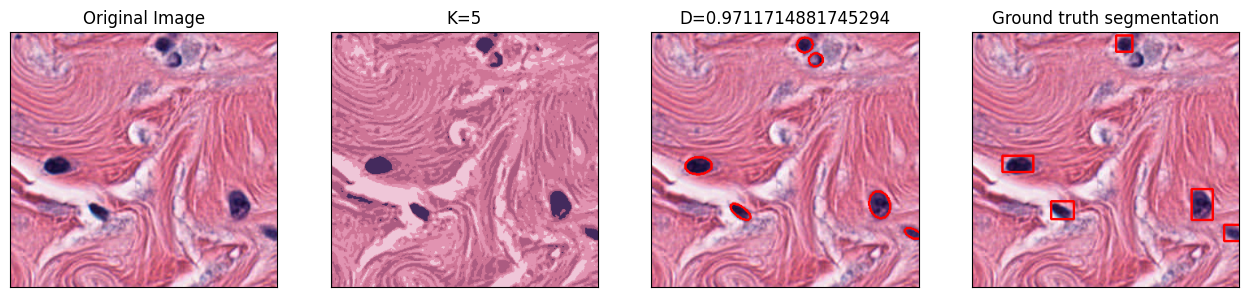

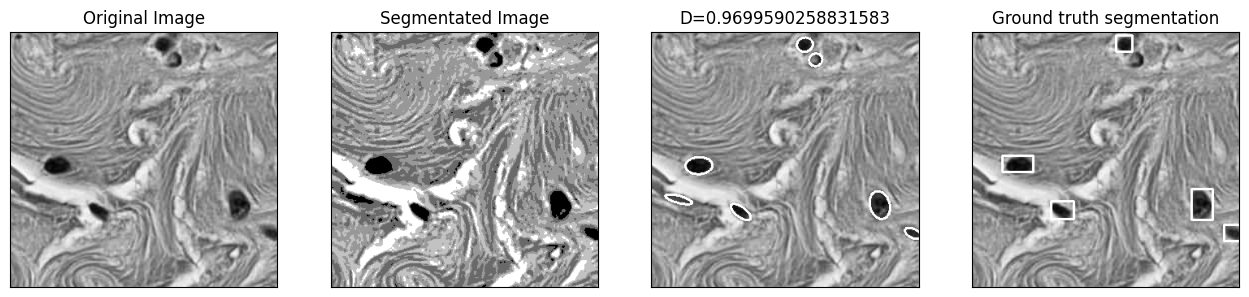

Chosen sample : 745


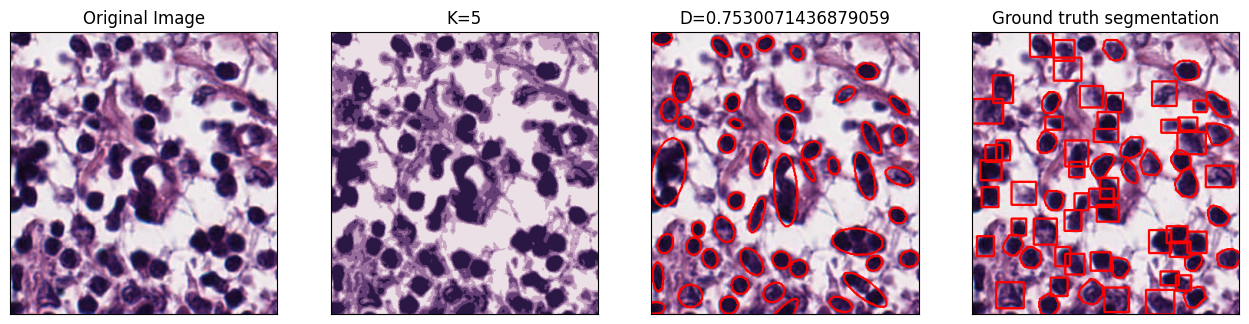

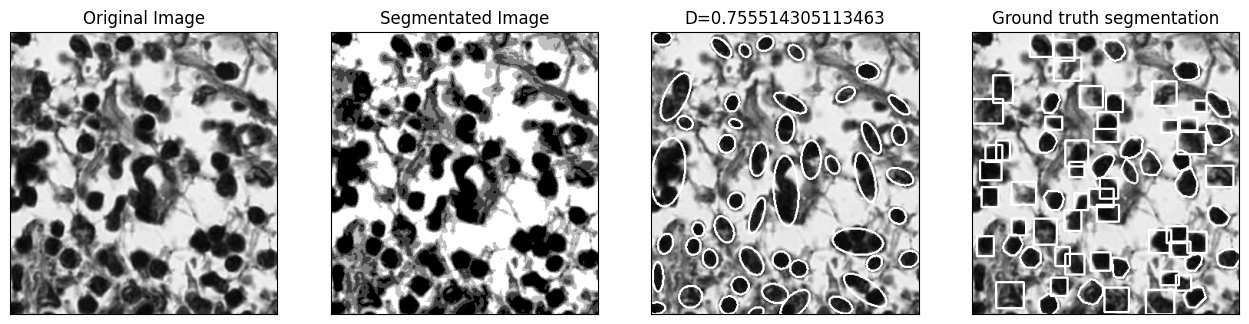

In [ ]:
n1 = 190
n2 = 727
n3 = 745

print("Chosen sample : {}".format(n1))
segment_kmeans(n1)
segment_kmeans_grayscale(n1)
print("Chosen sample : {}".format(n2))
segment_kmeans(n2)
segment_kmeans_grayscale(n2)
print("Chosen sample : {}".format(n3))
segment_kmeans(n3)
segment_kmeans_grayscale(n3)
print()

As we can observe from the above plot, K=5 is still dominant to obtain better masks. However, if we compare the results to the RGB plot, we can see that K=5 for grayscale seems to have a higher frequency. That means we will obtain better results for more images if we use grayscale and K=5. This can be concluded in the above figures.


---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.1.5: You have studied a number of other unsupervised segmentation methods in class. Pick one and compare the results to the K-means results (for the optimal K found above). Run your code on the RGB image.   <font>

---


From the different unsupervised segmentation methods seen in class, we selected GMM

In [ ]:
from sklearn import mixture

def gmm(img,K):
  #Reshape image to flattened array of pixels (3 levels deep for RGB)
  #Convert segmented image to grayscale
  if len(img.shape) == 3:
    Z = img.copy().reshape((-1,3))
  else:
    Z = img.copy().reshape((-1,1))
  
  Z = np.float32(Z)
  # fit GMM on Z
  clf = mixture.GaussianMixture(n_components=K, covariance_type='full')
  clf.fit(Z)

  # predict cluster membership from the fitted GMM 
  label = clf.predict(Z)

  #Using the output labels, map each point to the colour of its center
  center = np.uint8(clf.means_)
  out = center[label.flatten()]
  out = out.reshape((img.shape))  #output image with clustering

  return out

In [ ]:
def segment_gmm(n):
  img = rgb(imgs[n])
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  csv1 = csv(imgs[n])
  mask_ori = get_mask(imgs[n])
  mask_ori = cv2.cvtColor(mask_ori, cv2.COLOR_BGR2GRAY)

  #Calculate segmented image
  K = 5
  out_disp = gmm(img,K)

  #Plot
  plt.figure(figsize=(20,15))
  plt.subplot(151)
  plt.imshow(img)
  plt.title("Original Image"), plt.xticks([]), plt.yticks([])
  plt.subplot(152)
  plt.imshow(out_disp)
  plt.title("GMM={}".format(K)), plt.xticks([]), plt.yticks([])

  #Create a mask from only the darkest points (tumor)
  mask, ellipses = calc_mask(img,out_disp.copy())

  # #Plot mask
  # plt.subplot(153)
  # plt.imshow(mask,cmap='gray')
  # plt.title("Mask"), plt.xticks([]), plt.yticks([])

  #Using mask, detect tumors
  D = cmpt_dice(mask_ori,mask,K)
  plt.subplot(153)
  tumors_kMeans = img.copy()
  for ellipse in ellipses:
      cv2.ellipse(tumors_kMeans, ellipse, (255, 0, 0), 2)
  plt.imshow(tumors_kMeans)
  plt.title("D={}".format(D)), plt.xticks([]), plt.yticks([])

  #Overlay ground truth on original image
  img_disp = overlay_image(img,csv1)

  #Show ground truth
  plt.subplot(154)
  plt.imshow(img_disp)
  plt.title("Ground truth segmentation"), plt.xticks([]), plt.yticks([])
  plt.show()

  return mask

Chosen sample : 682
Kmeans segmentation


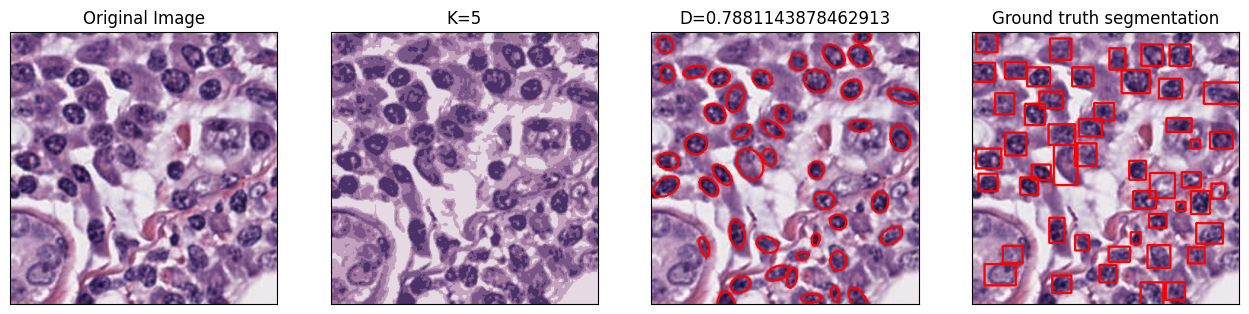

Gmm segmentation


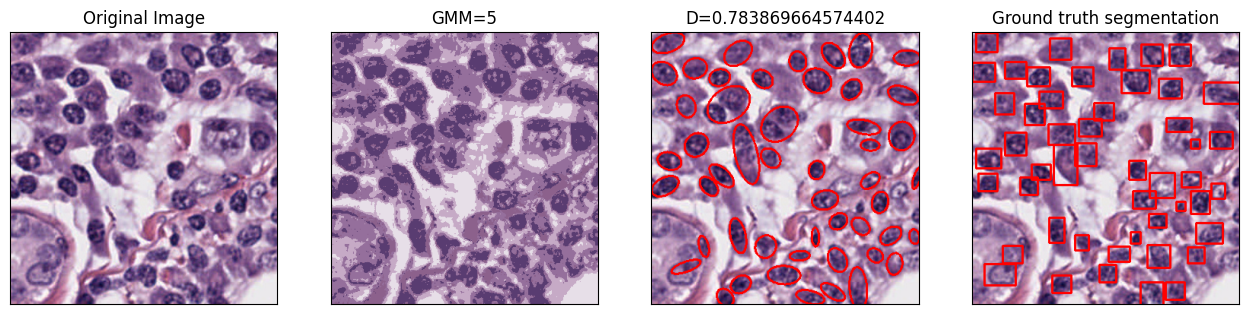

In [ ]:
#Choose random image
n = np.random.randint(0,len(imgs)-1)
n = 682
print("Chosen sample : {}".format(n))

print("Kmeans segmentation")
segment_kmeans(n)
print("Gmm segmentation")
segment_gmm(n)
print()

K-means was also compared to another unsupervised clustering technique: GMM. As we can observe, for K-means we get a dice coefficient of 0.788 while for GMM a dice coefficient of 0.784 is obtained, concluding that K-means works better for our algorithm.




---

 #### &#10148;<font face="serif" size=4 color='orange'> Qu 4.2:Segmentation - Supervised  <font>

---




---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.2.1: Describe the supervised approach being used  <font>

---


We settled on RF as this classification algorithm it is better suited for large datasets and is better at dealing with noise and outliers. ​See further analysis in the report



---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.2.2: Report the performance of your supervised segmentor on the training images  <font>

---


In [ ]:
train_data = dataFromUniqueIDs(train = True)
test_data = dataFromUniqueIDs(train = False)

#loading random train image
n = np.random.randint(0,len(train_data)-1)
# n=390
print(n)
img1 = rgb(imgs[n]) 
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
csv1 = csv(imgs[n])


def label_array(img,csv):
  '''
  returns mask with labels
  size is 1 X m*n
  '''
  labels = []
  #Create mask
  mask = np.zeros_like(img)
  with open(csv) as csvfile:
      reader = csv2.reader(csvfile, delimiter=',')
      next(reader) #skip header
      for r in reader:
        coords_x = r[9] #in string format
        coords_x = [int(x) for x in coords_x.split(',')] #converting to int
        coords_y = r[10] #in string format
        coords_y = [int(x) for x in coords_y.split(',')] #converting to int

        pts = []
        for i in range(len(coords_x)):
          pts.append([coords_x[i], coords_y[i]])
        pts = np.array(pts)
        # Fill the polygon with black color
        cv2.fillPoly(mask, [pts], (255, 255, 255))

  # Determine if a pixel is inside or outside of the polygon
  for pixel in mask.ravel():
    if pixel > 0:
        labels.append(1) #Pixel is inside the polygon
    else:
        labels.append(0) #Pixel is outside the polygon

  return labels

223


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import itertools

X = []
y = []
for index in train_data:
  img1 = rgb(imgs[index]) 
  img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
  csv1 = csv(imgs[index])
  labels1 = label_array(img1,csv1)
  X.append(img1.ravel())
  y.append(labels1)

X = [int(x) for x in itertools.chain(*X)]
y = [int(x) for x in itertools.chain(*y)]
#Train random forest classifer on 100 image
X = np.array(X).reshape(-1, 1)
y = np.array(y).reshape(-1, 1)
# Train the random forest classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X, y)

In [66]:
from joblib import dump, load
#Save the model to disk
#dump(clf, path+'rf.joblib')

# Load the model from disk
clf = load(path+'rf.joblib')

n: 178


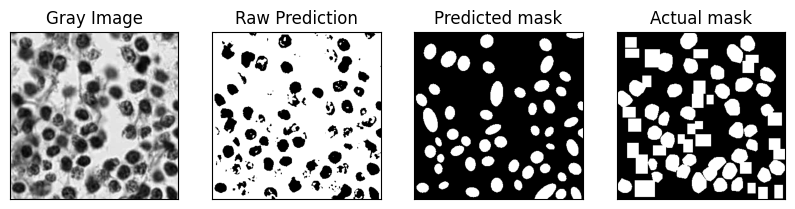

Confusion Matrix:
 [[67234  3126]
 [22235 18293]]
Full Test Accuracy: 0.7712917538417141


In [67]:
#Test on a validation image
from sklearn.metrics import confusion_matrix, accuracy_score

#loading random test image
n = np.random.choice(test_data)
n=178
print("n: {}".format(n))

img2 = rgb(imgs[n]) 
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
csv_2 = csv(imgs[n])

labels_2 = label_array(img2,csv_2)

#Reshaping actual mask
labels_2 = np.array(labels_2).reshape(img2.shape, order='C')

X_test = img2.ravel().reshape(-1, 1)
y_test = labels_2.reshape(-1, 1)

def test_classifier_plot(clf, X_test, y_test, img_test):
  actual_mask = np.array(y_test).reshape(img_test.shape, order='C')
  y_pred = clf.predict(X_test)

  #plotting mask from predicted label
  predicted_mask_raw = clf.predict(X_test)
  predicted_mask_raw = np.array(predicted_mask_raw).reshape(img_test.shape, order='C')
  predicted_mask_raw = np.invert(predicted_mask_raw.astype(np.uint8))


  out= k_means(predicted_mask_raw,3)
  predicted_mask = calc_mask(predicted_mask_raw,out)[0]
  predicted_mask = np.array(predicted_mask).astype(np.uint8)


  plt.figure(figsize=(10,10))
  plt.subplot(1,4,1), plt.imshow(img_test,cmap='gray')
  plt.title("Gray Image"), plt.xticks([]), plt.yticks([])
  plt.subplot(1,4,2), plt.imshow(predicted_mask_raw,cmap='gray')
  plt.title("Raw Prediction"), plt.xticks([]), plt.yticks([])
  plt.subplot(1,4,3), plt.imshow(predicted_mask,cmap='gray')
  plt.title("Predicted mask"), plt.xticks([]), plt.yticks([])
  plt.subplot(1,4,4), plt.imshow(actual_mask,cmap='gray')
  plt.title("Actual mask"), plt.xticks([]), plt.yticks([])
  plt.show()

    # calculate and print the confusion matrix
  cm = confusion_matrix(y_test, y_pred)
  print('Confusion Matrix:\n', cm)

  # calculate and print the full test accuracy
  acc = accuracy_score(y_test, y_pred)
  print('Full Test Accuracy:', acc)



def test_classifier(clf, X_test, y_test):
  y_pred = clf.predict(X_test)

  # calculate and print the confusion matrix
  cm = confusion_matrix(y_test, y_pred)
  print('Confusion Matrix:\n', cm)

  # calculate and print the full test accuracy
  acc = accuracy_score(y_test, y_pred)
  print('Full Test Accuracy:', acc)

test_classifier_plot(clf,X_test, y_test, img2)

In [70]:
import itertools
#Test on training images
def training_performance(loadSampleFromFile = False):
  #train on entire validation set
  X_train = []
  y_train = []
  if(loadSampleFromFile):
    X_train = np.load(path+'X_train.npy')
    y_train = np.load(path+'y_train.npy')
  else:
    for index in train_data[0:100]:
      img1 = rgb(imgs[index]) 
      img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
      csv1 = csv(imgs[index])
      labels1 = label_array(img1,csv1)
      X_train.append(img1.ravel())
      y_train.append(labels1)
    #Reshape
    X_train = [int(x) for x in itertools.chain(*X_train)]
    y_train = [int(x) for x in itertools.chain(*y_train)]
    X_train = np.array(X_train).reshape(-1, 1)
    y_train = np.array(y_train).reshape(-1, 1)
    #Save to file
    np.save(path+'X_train.npy',X_train)
    np.save(path+'y_train.npy',y_train)

  #train the random forest classifer
  test_classifier(clf,X_train, y_train)

training_performance(loadSampleFromFile = True)

Confusion Matrix:
 [[6985828 1671559]
 [1616671 2429191]]
Full Test Accuracy: 0.7411504726074408




---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.2.3: Report the performance of your supervised segmentor on the validation images  <font>

---


In [72]:
def validation_performance(loadSampleFromFile = False):
  #Test on entire validation set
  X_test = []
  y_test = []
  if(loadSampleFromFile):
    X_test = np.load(path+'X_validation.npy')
    y_test = np.load(path+'y_validation.npy')
  else:
    for index in test_data:
      img1 = rgb(imgs[index]) 
      img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
      csv1 = csv(imgs[index])
      labels1 = label_array(img1,csv1)
      X_test.append(img1.ravel())
      y_test.append(labels1)
    #Reshape
    X_test = [int(x) for x in itertools.chain(*X_test)]
    y_test = [int(x) for x in itertools.chain(*y_test)]
    X_test = np.array(X_test).reshape(-1, 1)
    y_test = np.array(y_test).reshape(-1, 1)
    #Save to file
    np.save(path+'X_validation.npy',X_test)
    np.save(path+'y_validation.npy',y_test)

  #Test the random forest classifer
  test_classifier(clf,X_test, y_test)

validation_performance(loadSampleFromFile = False)

Confusion Matrix:
 [[18397448  2861495]
 [ 4396058  4865293]]
Full Test Accuracy: 0.7622056655155419




---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.2.4: . Select a few samples (at least 3) from the validation images and compare the performance of the supervised and unsupervised methods (i) qualitatively and (ii) quantitatively. Discuss which method (supervised or unsupervised) has better performance.  <font>

---


Chosen sample : 1412


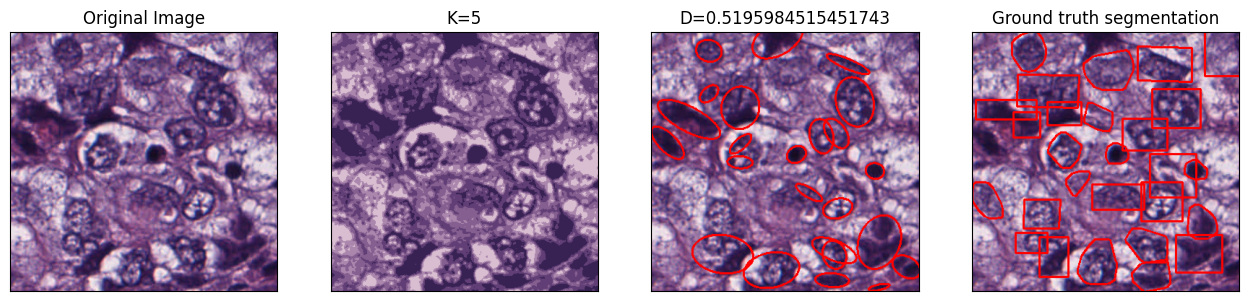

Confusion Matrix:
 [[67872  7564]
 [32993 25131]]
Accuracy: 0.6963387241689128


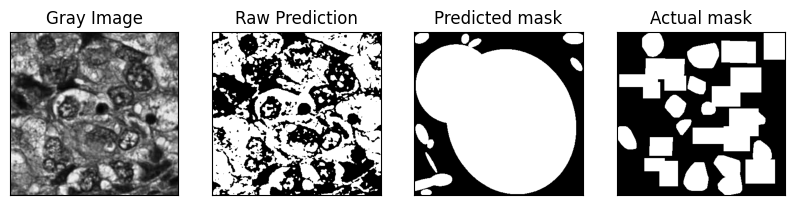

Confusion Matrix:
 [[53915 21521]
 [21745 36379]]
Full Test Accuracy: 0.6760557053009884


Chosen sample : 1671


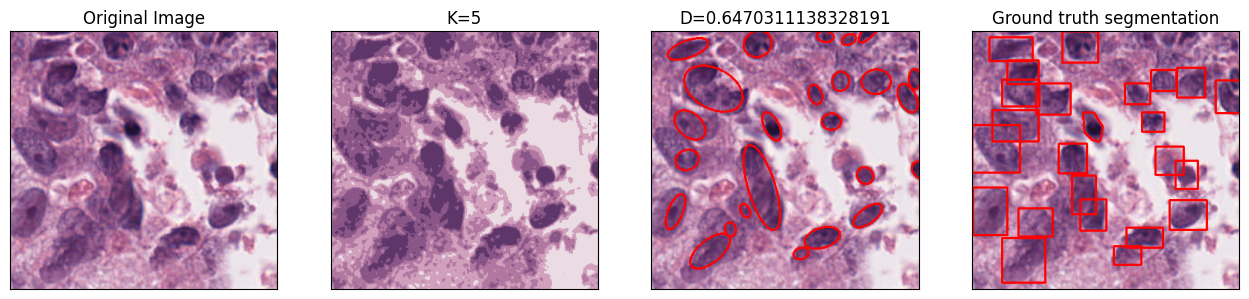

Confusion Matrix:
 [[81003  2457]
 [21881 19579]]
Accuracy: 0.8051713096381684


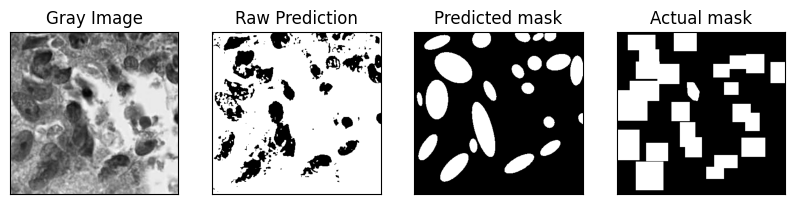

Confusion Matrix:
 [[79833  3627]
 [22074 19386]]
Full Test Accuracy: 0.7942603266090298


Chosen sample : 7


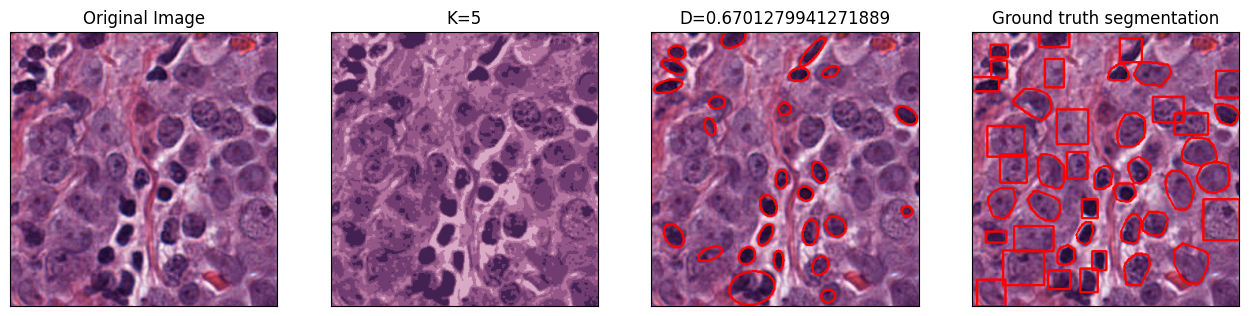

Confusion Matrix:
 [[72521  2640]
 [34747  8752]]
Accuracy: 0.6849233102983313


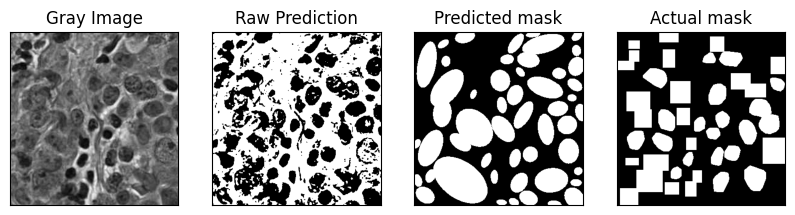

Confusion Matrix:
 [[57137 18024]
 [15284 28215]]
Full Test Accuracy: 0.7192988370133153


In [76]:
def supervised_plot(n):
  img_test = rgb(imgs[n]) 
  img_test = cv2.cvtColor(img_test, cv2.COLOR_BGR2GRAY)
  csv_test = csv(imgs[n])

  labels_2 = label_array(img_test,csv_test)

  #Reshaping actual mask
  labels_2 = np.array(labels_2).reshape(img_test.shape, order='C')

  X_test = img_test.ravel().reshape(-1, 1)
  y_test = labels_2.reshape(-1, 1)

  #Plot
  test_classifier_plot(clf,X_test, y_test, img_test)

def unsupervised_plot(n):
  img_test = rgb(imgs[n]) 
  img_test = cv2.cvtColor(img_test, cv2.COLOR_BGR2GRAY)
  csv_test = csv(imgs[n])

  labels_2 = label_array(img_test,csv_test)

  #Reshaping actual mask
  labels_2 = np.array(labels_2).reshape(img_test.shape, order='C').reshape(-1, 1)

  #Predicted mask
  mask1 = segment_kmeans(n)
  mask1 = cv2.threshold(mask1, 127, 1, cv2.THRESH_BINARY)[1]
  mask1 = mask1.ravel().reshape(-1, 1)  

  # Calculate the confusion matrix
  cm = confusion_matrix(labels_2, mask1)
  # Calculate the accuracy
  acc = accuracy_score(labels_2, mask1)

  print('Confusion Matrix:\n', cm)
  print('Accuracy:', acc)

#loading random test image
n1 = np.random.choice(test_data)
n2 = np.random.choice(test_data)
n3 = np.random.choice(test_data)



print("Chosen sample : {}".format(n1))
unsupervised_plot(n1)
supervised_plot(n1)
print("\n")
print("Chosen sample : {}".format(n2))
unsupervised_plot(n2)
supervised_plot(n2)
print("\n")
print("Chosen sample : {}".format(n3))
unsupervised_plot(n3)
supervised_plot(n3)



---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 4.2.5: For a given subject, which nuclei group can be segmented easily? Discuss by showing some sample visualizations.  <font>

---


1


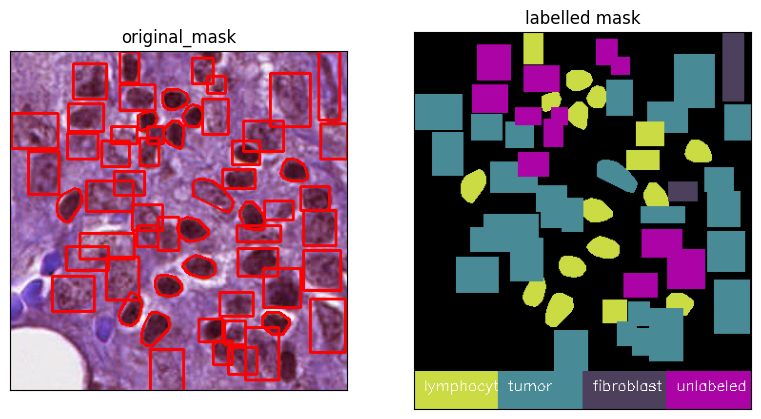

In [74]:
#loading random train image
n = np.random.randint(0,len(train_data)-1)
n=1
print(n)
img1 = rgb(imgs[n]) 
# img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
csv1 = csv(imgs[n])

#Label different tumors
def label_tumors_array(img,csv):
  '''
  returns mask with labels
  size is 1 X m*n
  '''
  labels = []
  colours = {}
  #Create mask
  mask = np.zeros_like(img)
  with open(csv) as csvfile:
      reader = csv2.reader(csvfile, delimiter=',')
      next(reader) #skip header
      for r in reader:
        raw_type = r[1]
        coords_x = r[9] #in string format
        coords_x = [int(x) for x in coords_x.split(',')] #converting to int
        coords_y = r[10] #in string format
        coords_y = [int(x) for x in coords_y.split(',')] #converting to int

        pts = []
        for i in range(len(coords_x)):
          pts.append([coords_x[i], coords_y[i]])
        pts = np.array(pts)
        # Fill the polygon with appropriate tumor colour
        if raw_type not in colours:
          colours[raw_type] = np.random.randint(0,255,3).tolist()
        cv2.fillPoly(mask, [pts], colours[raw_type])

  return mask, colours


m,c = label_tumors_array(img1,csv1)
original_mask = overlay_image(img1,csv1)



# Create a blank image for the color legend
legend_height = 40  # height of the legend
legend_width = img1.shape[1]  # width of the legend (same as the original image)
legend = np.zeros((legend_height, legend_width, 3), dtype=np.uint8)

# Draw rectangles with colors and labels on the legend
for i, label in enumerate(c.keys()):
    color = c[label]
    x1 = i * legend_width // len(c)  # x-coordinate of the left edge of the rectangle
    x2 = (i + 1) * legend_width // len(c)  # x-coordinate of the right edge of the rectangle
    cv2.rectangle(legend, (x1, 0), (x2, legend_height), color, -1)  # draw the filled rectangle
    cv2.putText(legend, label, (x1 + 10, legend_height // 2), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)  # add the label

# Concatenate the original image and the color legend vertically
result = cv2.vconcat([m, legend])



plt.figure(figsize=(20,20))
plt.subplot(1,4,1), plt.imshow(original_mask,cmap='gray')
plt.title("original_mask"), plt.xticks([]), plt.yticks([])
plt.subplot(1,4,2), plt.imshow(result)
plt.title("labelled mask"), plt.xticks([]), plt.yticks([])
plt.show()






---

#&#10148;<font face="serif" size=5 color='cyan'> ***Qu 5:Detecting and Counting Tumors*** <font>

---


---

 #### &#10148;<font face="serif" size=4 color='orange'> Qu 5.1:Preparing the data  <font>

---
---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.1: Convert input images and masks to grayscale.   <font>

---




In [ ]:
def to_grayscale(imgs):
  """
  Converts images and masks to grayscale 
  imgs is the list of files

  """
    # write all images and masks into lists


  images = [cv2.cvtColor(rgb(i), cv2.COLOR_BGR2GRAY) for i in imgs]
  masks = [cv2.cvtColor(get_mask(i), cv2.COLOR_BGR2GRAY) for i in imgs]

    
  # make sure we have the same number of masks and images 
  assert len(images) == len(masks)
    
  return images, masks

images, masks = to_grayscale(imgs)

---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.2: Multiply the mask and the original image to obtain the regions of interest. (Note: It is possible that size of image and mask differ by a number, to avoid this slice either the image or the mask so that both are of the same size)   <font>

---

In [ ]:
# make sure the image and mask are of the same size 
min_shape = (min(img.shape[0] for img in images + masks), min(img.shape[1] for img in images + masks))
images = [img[:min_shape[0], :min_shape[1]] for img in images]
masks = [mask[:min_shape[0], :min_shape[1]] for mask in masks]

# multiply mask and original grey image to obtain regions of interest 
roi = [img * (mask) for img, mask in zip(images, masks)]

---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.3: Remove the background noise in the resultant image. For the purpose of better understanding, a sample image after these operations are shown in Fig. 2.<font>

---

In [ ]:
# remove background noise to isolate regions of interest
denoised_imgs = []
for n, r in enumerate(roi): 
  m = 255 - masks[n]
  result_0 = np.zeros_like(m)
  result_0[m > 180] = 255
  denoised = cv2.bitwise_and(r, r, mask=result_0)
  denoised_imgs.append(denoised)


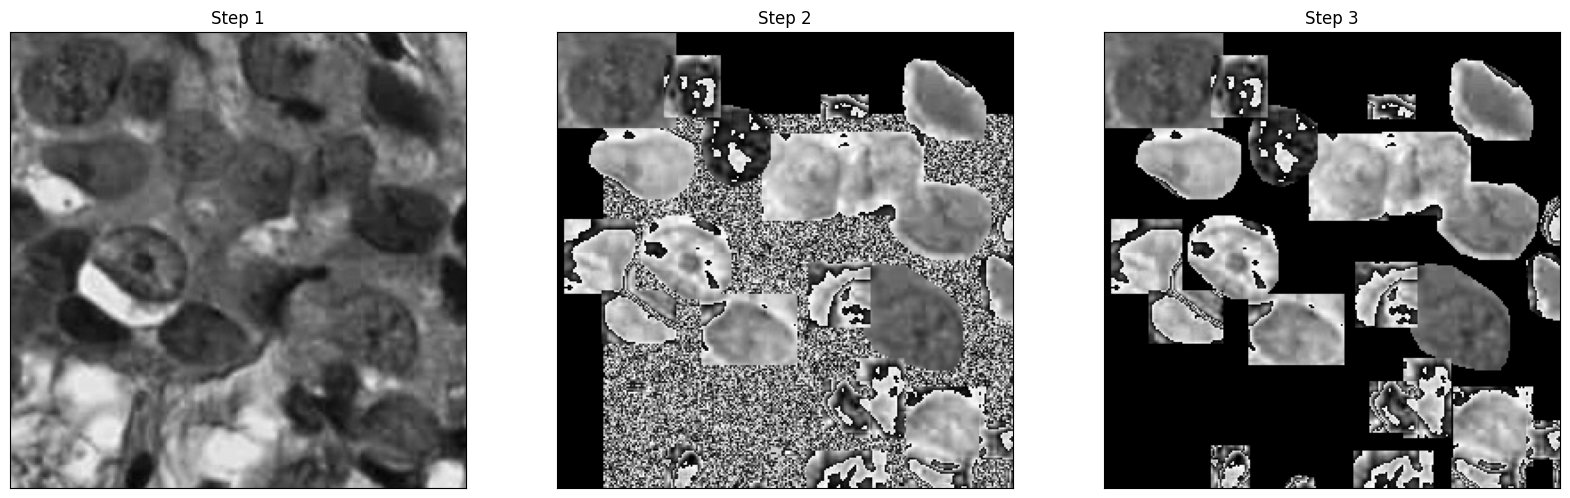

In [ ]:
# chose a random image
n = 70

# recreate the image in the pdf (step 1 to 3)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 20))
ax1.imshow(images[n], cmap="gray")
ax1.set_title("Step 1")
ax2.imshow(roi[n], cmap="gray"), ax1.set_xticks([]), ax1.set_yticks([])
ax2.set_title("Step 2")
ax3.imshow(denoised_imgs[n], cmap="gray"), ax2.set_xticks([]), ax2.set_yticks([])
ax3.set_title("Step 3"), ax3.set_xticks([]), ax3.set_yticks([])
plt.show()

---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.4: Extract features of the resultant image that has different pathological structures (blobs) <font>
  ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.5: Using these features, build a detection model to segregate tumor pathologies from non-tumor pathologies. <font>
 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.6: The target label for tumors and non-tumors can be obtained from the corresponding csv file of the image. <font>
 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.7: The count for this image would be the number of tumor in the given image i.e, count the number of instances of tumor for the given image. The ground truth count can be obtained by reporting the number of instances of tumor from the corresponding csv file. <font>


---

In [ ]:
# define all the image features and labels
img_blobs = [] # contains isolated blobs extracted from step 3 image. img_blobs[100][4] returns the 5th blob in image 101
img_blob_labels = [] # contains the label (tumor/nontumor) of the blob. img_blob_labels[100][4] returns the label of the 5th blob in image 101
img_n_tumors = [] # contains the number of tumors in each image. img_n_tumors[100] returns the number of tumors in image 100. 
img_blob_descriptors = [] # contains SIFT descriptors for isolated blobs. img_blob_descriptors[100][4] returns the descriptors of the 5th blob in image 101
img_blob_keypoins = [] # contains SIFT keypoints for isolated blobs. img_blob_keypoins[100][4] returns the keypoints of the 5th blob in image 101

def segragate_blobs(sift, img,csv, draw=False):
  """
  Segregates, isolates, and processes pathological structures in an image. 

  Parameters: 
    sift: sift value
    img: image to process 
    csv: csv corresponding to the input image (img)
    draw: If true, returns the "Step 6" figure (similar to the handout pdf).

  Returns: 
   num_tumors: number of tumors in img
   blobs: list of blob images extracted from img
   blob_labels: list of blob labels
   keypoints: keypoints of extracted blobs
   descriptors: descriptors of extracted blobs
  """
  img_copy = img.copy()
  overlay = cv2.cvtColor(img.copy(), cv2.COLOR_GRAY2BGR)
  num_tumors = 0
  blobs = []
  blob_labels = []
  keypoints = []
  descriptors = []


  with open(csv) as csvfile:
      reader = csv2.reader(csvfile, delimiter=',')
      next(reader) #skip header
      for r in reader:
        coords_x = r[9] #in string format
        coords_x = [int(x) for x in coords_x.split(',')] #converting to int
        coords_y = r[10] #in string format
        coords_y = [int(x) for x in coords_y.split(',')] #converting to int
        raw_classification = r[1]
    
        pts = []
        for i in range(len(coords_x)):
          pts.append([coords_x[i], coords_y[i]])
        pts = np.array(pts)

        # separate blobs into their own image      
        mask = np.zeros_like(img_copy)
        cv2.fillPoly(mask, np.int32([pts]), (255, 255, 255))

        roi = cv2.bitwise_and(img_copy, mask)
        # remove any empty blob (if all black)
        if cv2.mean(roi)[0] != 0:


        # run SIFT on blob
          kp, des = sift.detectAndCompute(roi, None)

          if des is None: 
            continue
          if des.shape[0] < 10:
            continue


          kp = sorted(kp, key=lambda x: x.response, reverse=True)

          # Keep only the top 10 keypoints and descriptors
          kp = kp[:10]
          des = des[:10,:]

          blobs.append(roi)
          blob_labels.append(raw_classification)

          keypoints.append(kp)
          descriptors.append(des)

          img2 = cv2.drawKeypoints(roi, kp, None, flags=0)

        # count tumors
          if raw_classification == "tumor":
            num_tumors += 1
          
          if draw: 
            # Draw the polyline shape
            if raw_classification == "tumor":
              cv2.polylines(overlay, [pts], isClosed=True, color=(0, 0, 255), thickness=2)
            else: 
              cv2.polylines(overlay, [pts], isClosed=True, color=(255, 0, 0), thickness=2)

            
  if draw:
    return num_tumors, blobs, blob_labels, keypoints, descriptors, overlay

  return num_tumors, blobs, blob_labels, keypoints, descriptors


sift = cv2.xfeatures2d.SIFT_create(nfeatures=10)

# loop through all images and process pathological structures and labels
for i, _ in enumerate(imgs):
  n_tumor, blobs, blob_labels, keypoints, descriptors = segragate_blobs(sift, denoised_imgs[i],csv(imgs[i]))
  assert len(blobs) == len(blob_labels) == len(keypoints) == len(descriptors)
  img_n_tumors.append(n_tumor)
  img_blobs.append(blobs)
  img_blob_labels.append(blob_labels)
  img_blob_descriptors.append(descriptors)
  img_blob_keypoins.append(keypoints)

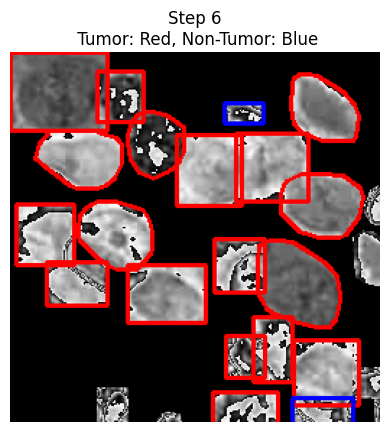

In [ ]:
_, _, _, _, _, overlay = segragate_blobs(sift, denoised_imgs[n],csv(imgs[n]), draw=True)
plt.figure()
plt.title("Step 6\n Tumor: Red, Non-Tumor: Blue")
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# ---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.1.8: Repeat the steps mentioned above, to loop over all the images for the subjects in train subjects.csv to construct a python data frame with Xtrain as features and Ytrain as the target label of tumors and non-tumors. Similarly, create Xval and Yval for the images of subjects in val subjects.csv. <font>

---

In [ ]:
# create training set 
train_idx = dataFromUniqueIDs(True)
X_train = [img_blob_descriptors[i] for i in train_idx] # X features are SIFT descriptors [12000 sift features] = [1000[12]] X_train[4][8] # image 4, blob 8
X_train = [item.flatten() for sublist in X_train for item in sublist]
y_train_all_labels = [img_blob_labels[i] for i in train_idx]
y_train_all_labels = [item for sublist in y_train_all_labels for item in sublist]
y_train = [img_blob_labels[i] for i in train_idx]
y_train = [item for sublist in y_train for item in sublist]
y_train = ['nontumor' if c != 'tumor' else 'tumor' for c in y_train]

assert len(X_train) == len(y_train)

# create validation set 
validation_idx = dataFromUniqueIDs(False)
X_validation = [img_blob_descriptors[i] for i in validation_idx]
X_validation = [item.flatten() for sublist in X_validation for item in sublist]
y_validation = [img_blob_labels[i] for i in validation_idx]
y_validation_all_labels = [item for sublist in y_validation for item in sublist]
y_validation = [item for sublist in y_validation for item in sublist]
y_validation = ['nontumor' if c != 'tumor' else 'tumor' for c in y_validation]


['tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'fibroblast', 'fibroblast', 'fibroblast', 'lymphocyte', 'fibroblast', 'unlabeled', 'lymphocyte', 'unlabeled', 'unlabeled', 'unlabeled', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'fibroblast', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'tumor', 'plasma_cell', 'lymphocyte', 'plasma_cell', 'plasma_cell', 'lymphocyte', 'plasma_cell', 'lymphocyte', 'lymphocyte', 'lymphocyte', 'lymphocyte', 'lymphocyte', 'lymphocyte', 'plasma_cell', 'lymphocyte', 'lymphocyte', 'lymphocyte', 'lymphocyte', 'lymphocyte', 'unlabeled', 'fibroblast', 'lymphocyte', 'lymphocyte', 'unlabeled', 'lymphocyte', 'lymphocyte', 'unlabeled', 'lymphocyte', 'fibroblas


---

 #### &#10148;<font face="serif" size=4 color='orange'> Qu 5.2: Classification Framework <font>

---
---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.2.1: Report performance metrics of the detection model for both training and validation images. <font>

---

In [ ]:
from sklearn.svm import SVC

#Shrink training set

#with kernel=poly
#4000:6000 seems to make it worse
#X_Train = X_train[0:4000]+X_train[7000:15000] Accuracy: 71.85%
#X_Train = X_train[0:4000]+X_train[7000:11000] Accuracy: 71.10%
#X_Train = X_train[0:4000]+X_train[7000:10000] Accuracy: 71.17%
#X_Train = X_train[0:4000]+X_train[12000:15000] Accuracy: 71.14%
#X_Train = X_train[12000:15000] Accuracy: 69.64%
#X_Train = X_train[10000:15000] Accuracy: 69.71%
#X_Train = X_train[0:4000]+X_train[12000:15000]+X_train[18000:20000] Accuracy: 71.89%
#X_Train = X_train[0:5000]+X_train[12000:15000]+X_train[18000:21000] Accuracy: 71.85%
#with kernel = rbf
#X_Train = X_train[0:4000]+X_train[12000:15000]+X_train[18000:20000] Accuracy: 71.94%
#X_Train = X_train[0:4500]+X_train[12000:15000]+X_train[18000:21000] Accuracy: 72.49%
#X_Train = X_train[0:5000]+X_train[12000:15000]+X_train[18000:21000] Accuracy: 72.71%
#X_Train = X_train[0:21000] Accuracy: 73.22%
#X_Train = X_train[0:5000]+X_train[6000:21500] Accuracy: 73.28%
#X_Train = X_train[0:5000] C=10 69.21%
#X_Train = X_train[0:5000] C=0.01 Accuracy: 61.36%
#X_Train = X_train[0:5000]+X_train[6000:15000] C =100  Accuracy: 71.53%

X_Train = X_train[0:5000]+X_train[6000:15000]
y_Train = y_train[0:5000]+y_train[6000:15000]

# Define the SVM classifier
svm = SVC(kernel='rbf',C=100)

# Train the SVM classifier
svm.fit(X_Train, y_Train)



SVC(C=100)

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# Make predictions on the validation data
y_pred_v = svm.predict(X_validation)

# Calculate the accuracy of the SVM classifier
accuracy = accuracy_score(y_validation, y_pred_v)

# Print the classification report and accuracy score
print(classification_report(y_validation, y_pred_v))
print("Accuracy: {:.2f}%".format(accuracy * 100))


              precision    recall  f1-score   support

    nontumor       0.75      0.80      0.77      2509
       tumor       0.64      0.59      0.61      1580

    accuracy                           0.72      4089
   macro avg       0.70      0.69      0.69      4089
weighted avg       0.71      0.72      0.71      4089

Accuracy: 71.53%


In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# Make predictions on the training data
y_pred_t = svm.predict(X_train)

# Calculate the accuracy of the SVM classifier
accuracy = accuracy_score(y_train, y_pred_t)

# Print the classification report and accuracy score
print(classification_report(y_train, y_pred_t))
print("Accuracy: {:.2f}%".format(accuracy * 100))



              precision    recall  f1-score   support

    nontumor       0.93      0.95      0.94      9850
       tumor       0.93      0.91      0.92      7274

    accuracy                           0.93     17124
   macro avg       0.93      0.93      0.93     17124
weighted avg       0.93      0.93      0.93     17124

Accuracy: 93.33%


---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.2.2: After detecting the tumor for all validation images, count the number of detector tumors in the image. Report the root mean squarred error (RMSE) for this task of counting tumors. <font>

---

In [ ]:
from sklearn.metrics import mean_squared_error
num_pred_tumors_t =[] #holds number of tumors per image
y_pred_t_num = []
y_train_num = []

# Convert to numerical data
for i in range(len(y_pred_t)):
  if y_pred_t[i]=="tumor":
    y_pred_t_num.append(1)
  else:
    y_pred_t_num.append(0)

for i in range(len(y_train)):
  if y_train[i]=="tumor":
    y_train_num.append(1)
  else:
    y_train_num.append(0)

# Count num tumors train
index = 0
for ind in train_idx:
  count = 0
  for j in range(len(img_blobs[ind])):
    if  y_pred_t_num[index]==1:#if tumor add to count
      index += 1
      count +=1
  num_pred_tumors_t.append(count)
#img_n_tumors = num tumours per image

print(num_pred_tumors_t)


# RMSE for training set
mean_squared_error(y_train_num, y_pred_t_num)

[9, 12, 14, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

0.06669002569493108

In [ ]:
num_pred_tumors_v =[]
y_pred_v_num = []
y_val_num = []

# Convert to numerical data
for i in range(len(y_pred_v)):
  if y_pred_v[i]=="tumor":
    y_pred_v_num.append(1)
  else:
    y_pred_v_num.append(0)

for i in range(len(y_validation)):
  if y_train[i]=="tumor":
    y_val_num.append(1)
  else:
    y_val_num.append(0)

# Count num tumors validation
index = 0
for ind in validation_idx:
  count = 0
  for j in range(len(img_blobs[ind])):
    if  y_pred_t_num[index]==1:#if tumor add to count
      index += 1
      count +=1
  num_pred_tumors_v.append(count)
#img_n_tumors = num tumours per image

print(num_pred_tumors_v)

# RMSE for training set
mean_squared_error(y_val_num, y_pred_v_num)

[8, 3, 11, 1, 13, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


0.4715089263878699

---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.2.3: Is there a difference in the performance if you use the ‘original image’ in Fig. 2 (i.e. the unmasked image (Step 1)) instead of only classifying each of the provided pathological regions (i.e. the masked regions)? Provide a qualitative and quantitative discussion of your results. (Hint: To answer this you will need to recreate Xtrain, Ytrain, Xval, and Yval. You are required to use **the** features from the original image for this task.) <font>

---

In [ ]:
X_Train_no_mask = []
y_Train_no_mask = []


sift = cv2.xfeatures2d.SIFT_create(nfeatures=10)
#run SIFT on training imgs

for ind in train_idx:
  kp, des = sift.detectAndCompute(denoised_imgs[ind], None)
  if des is None: 
    continue
  if des.shape[0] < 10:
    continue
  des = des[:10,:]
  X_Train_no_mask.append(des)
  y_Train_no_mask.append(img_n_tumors[ind])
  


In [ ]:
# Flatten array to fit SVM
X_Train_no_mask_flat = np.array([val.reshape(-1) for val in X_Train_no_mask])
print(X_Train_no_mask_flat[1])
print(len(X_Train_no_mask_flat))


[ 5. 11. 19. ...  4.  6. 50.]
1201


In [ ]:
X_Val_no_mask = []
y_Val_no_mask = []


sift = cv2.xfeatures2d.SIFT_create(nfeatures=10)
#run SIFT on training imgs

for ind in validation_idx:
  kp, des = sift.detectAndCompute(denoised_imgs[ind], None)
  if des is None: 
    continue
  if des.shape[0] < 10:
    continue
  des = des[:10,:]
  X_Val_no_mask.append(des)
  y_Val_no_mask.append(img_n_tumors[ind])

In [ ]:
# Flatten array to fit SVM
X_Val_no_mask_flat = np.array([val.reshape(-1) for val in X_Val_no_mask])
print(X_Val_no_mask_flat[1])
print(len(X_Val_no_mask_flat))

[ 5. 74. 49. ... 20.  1.  0.]
288


In [ ]:
# Define the SVM classifier
svm_no_mask = SVC(kernel='rbf')

# Train the SVM classifier
svm_no_mask.fit(X_Train_no_mask_flat, y_Train_no_mask)

SVC()

In [ ]:
# Make predictions on the training data
# Prediction = num tumors so often off bby a few classifications which messes up acc
y_pred_no_mask_t = svm_no_mask.predict(X_Train_no_mask_flat)


# Calculate the accuracy of the SVM classifier
accuracy = accuracy_score(y_Train_no_mask, y_pred_no_mask_t)

# Print the classification report and accuracy score
print(classification_report(y_Train_no_mask, y_pred_no_mask_t))
print("Accuracy: {:.2f}%".format(accuracy * 100))

              precision    recall  f1-score   support

           0       0.39      1.00      0.56       447
           1       0.00      0.00      0.00        55
           2       0.00      0.00      0.00        36
           3       0.00      0.00      0.00        30
           4       0.00      0.00      0.00        46
           5       1.00      0.05      0.09        43
           6       1.00      0.02      0.05        42
           7       1.00      0.02      0.04        50
           8       1.00      0.31      0.47        42
           9       1.00      0.38      0.55        45
          10       1.00      0.16      0.28        55
          11       1.00      0.06      0.11        35
          12       1.00      0.02      0.05        42
          13       0.00      0.00      0.00        35
          14       1.00      0.09      0.16        35
          15       1.00      0.12      0.22        41
          16       1.00      0.10      0.18        31
          17       0.00    

/usr/local/lib/python3.9/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.9/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.9/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [ ]:
# Make predictions on the validation data
# Prediction = num tumors so often off bby a few classifications which messes up acc
y_pred_no_mask_v = svm_no_mask.predict(X_Val_no_mask_flat)


# Calculate the accuracy of the SVM classifier
accuracy = accuracy_score(y_Val_no_mask, y_pred_no_mask_v)

# Print the classification report and accuracy score
print(classification_report(y_Val_no_mask, y_pred_no_mask_v))
print("Accuracy: {:.2f}%".format(accuracy * 100))



              precision    recall  f1-score   support

           0       0.39      1.00      0.56       112
           1       0.00      0.00      0.00        13
           2       0.00      0.00      0.00         7
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        14
           5       0.00      0.00      0.00        11
           6       0.00      0.00      0.00         6
           7       0.00      0.00      0.00        10
           8       0.00      0.00      0.00        12
           9       0.00      0.00      0.00        19
          10       0.00      0.00      0.00        12
          11       0.00      0.00      0.00        17
          12       0.00      0.00      0.00         7
          13       0.00      0.00      0.00         6
          14       0.00      0.00      0.00         7
          15       0.00      0.00      0.00         4
          16       0.00      0.00      0.00         6
          17       0.00    

/usr/local/lib/python3.9/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.9/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.9/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


---

 ##### &#10148;<font face="serif" size=3 color='green'> Qu 5.2.4: Based on the features you used in the detection model, what pathological structures are easier to segregate from tumors? Justify your answer using appropriate metrics. <font>

---

In [ ]:


from sklearn.svm import SVC

#Shrink training set


X_Train_all_labels = X_train[0:5000]
y_Train_all_labels = y_train_all_labels[0:5000]

# Define the SVM classifier
svm = SVC(kernel='rbf',C=100)

# Train the SVM classifier
svm.fit(X_Train_all_labels, y_Train_all_labels)


SVC(C=100)

In [ ]:

from sklearn.metrics import classification_report, accuracy_score

# Make predictions on the validation data
y_pred_v_all_labels = svm.predict(X_validation)

# Calculate the accuracy of the SVM classifier
accuracy = accuracy_score(y_validation_all_labels, y_pred_v_all_labels)

# Print the classification report and accuracy score
print(classification_report(y_validation, y_pred_v))
print("Accuracy: {:.2f}%".format(accuracy * 100))

              precision    recall  f1-score   support

    nontumor       0.75      0.80      0.77      2509
       tumor       0.64      0.59      0.61      1580

    accuracy                           0.72      4089
   macro avg       0.70      0.69      0.69      4089
weighted avg       0.71      0.72      0.71      4089

Accuracy: 46.81%


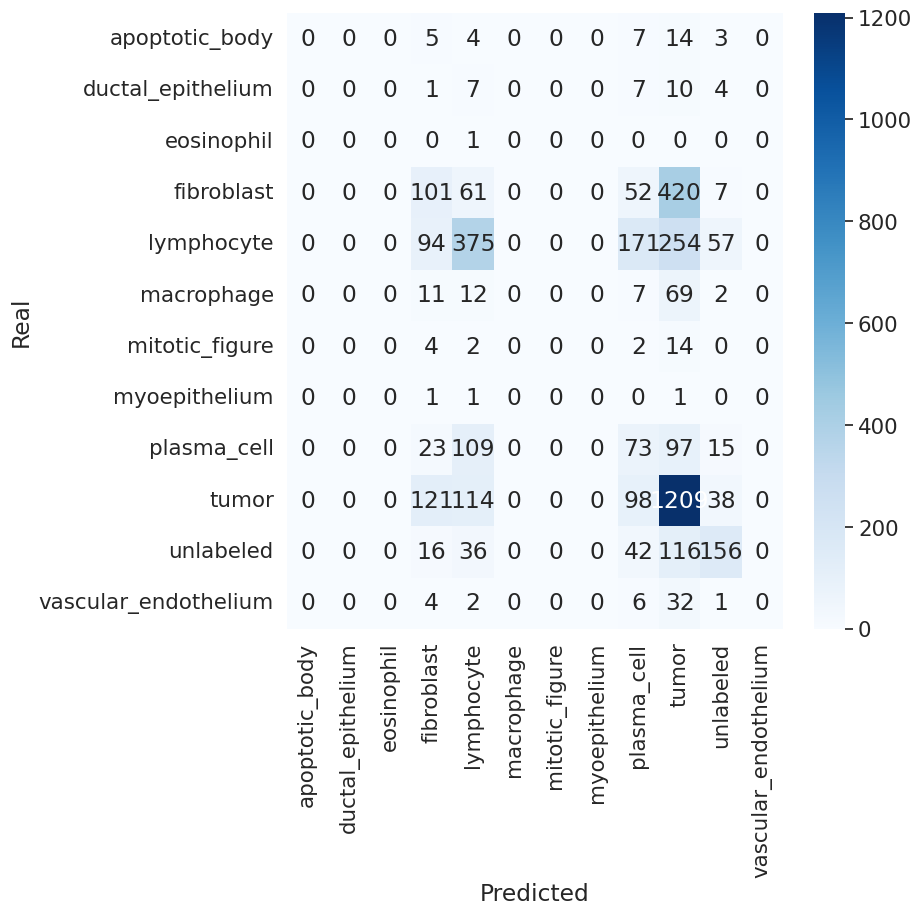

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn


# Confusion matrix
cm = confusion_matrix(y_validation_all_labels, y_pred_v_all_labels)
labels = np.unique(y_validation_all_labels)

# Plot
fig, ax = plt.subplots(figsize=(8,8))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=labels, yticklabels=labels)#sets labels correctly

ax.set_xlabel('Predicted')
ax.set_ylabel('Real')

plt.show()